In [1]:
# ETF net flows of SPY, RSP and VOO (Section 3.2.2)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The clean files are saved straight into the folder with the regression notebooks
OUT = "../Regressions and relevant csvs/"

In [2]:
# CRSP Mutual Fund data (WRDS): month-end total net assets (TNA, in $ millions) and the monthly
# total return per share, November 2015 to December 2025.
# Net flows are not reported, so they are implied from TNA and the return:
#   net flow = TNA(t) - TNA(t-1) * (1 + R(t)),   flow = net flow / TNA(t-1)
def implied_flows(file):
    raw = pd.read_excel(file)
    fund = pd.DataFrame({
        "date": pd.to_datetime(raw["Date"]) + pd.offsets.MonthEnd(0),
        "tna": raw["Total Net Assets as of Month End"],
        "ret": raw["Total Return per Share as of Month End"],
    }).sort_values("date").reset_index(drop=True)
    fund["net_flow"] = fund["tna"] - fund["tna"].shift(1) * (1 + fund["ret"])
    fund["flow"] = fund["net_flow"] / fund["tna"].shift(1)
    return fund.dropna().reset_index(drop=True)      # the first month has no lagged TNA

spy = implied_flows("SPY Monthly.xlsx")
rsp = implied_flows("RSP Monthly.xlsx")
voo = implied_flows("VOO Monthly.xlsx")
print(len(spy), "months from", spy["date"].min().date(), "to", spy["date"].max().date())

121 months from 2015-12-31 to 2025-12-31


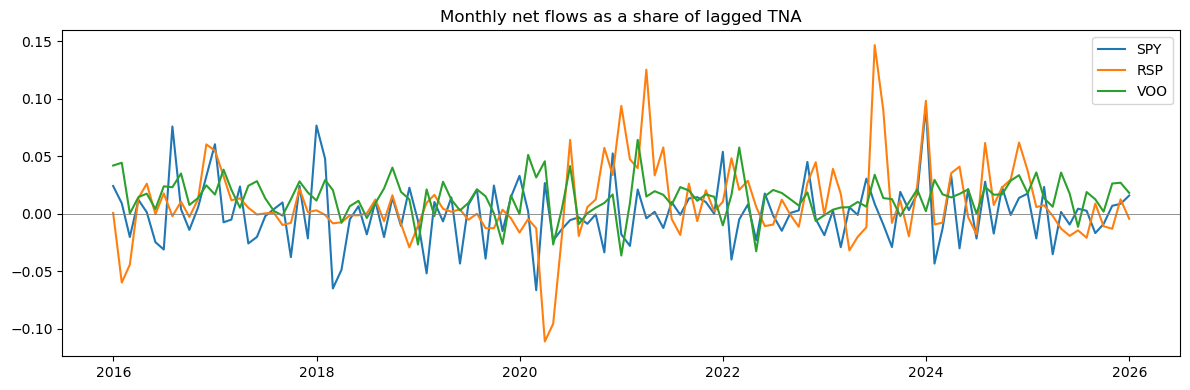

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(spy["date"], spy["flow"], label="SPY")
plt.plot(rsp["date"], rsp["flow"], label="RSP")
plt.plot(voo["date"], voo["flow"], label="VOO")
plt.axhline(0, color="grey", lw=0.6)
plt.title("Monthly net flows as a share of lagged TNA")
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Fund size (Section 3.1) and SPY net flows in dollars (Section 5.2)
print(f"SPY total net assets, December 2025: ${spy['tna'].iloc[-1] / 1000:.0f} billion")
print(f"VOO total net assets, December 2025: ${voo['tna'].iloc[-1] / 1000:.0f} billion")

spy_bn = spy.set_index("date").loc["2016-01-31":, "net_flow"] / 1000      # $ billion, 2016-2025
q = spy_bn.quantile([0.10, 0.25, 0.75, 0.90])
print(f"SPY monthly net flows: half of the months between {q[0.25]:.1f} and {q[0.75]:.1f} billion, "
      f"80% between {q[0.10]:.1f} and {q[0.90]:.1f} billion")
print(f"Largest outflow {spy_bn.min():.1f} billion ({spy_bn.idxmin():%B %Y}), "
      f"largest inflow {spy_bn.max():.1f} billion ({spy_bn.idxmax():%B %Y})")

SPY total net assets, December 2025: $712 billion
VOO total net assets, December 2025: $839 billion
SPY monthly net flows: half of the months between -5.2 and 5.6 billion, 80% between -11.1 and 11.7 billion
Largest outflow -22.4 billion (March 2025), largest inflow 40.8 billion (December 2023)


In [5]:
spy[["date", "flow"]].rename(columns={"flow": "flow_spy"}).to_csv(OUT + "spy_clean.csv", index=False)
rsp[["date", "flow"]].rename(columns={"flow": "flow_rsp"}).to_csv(OUT + "rsp_clean.csv", index=False)
voo[["date", "flow"]].rename(columns={"flow": "flow_voo"}).to_csv(OUT + "voo_clean.csv", index=False)